In [1]:
print("radha")

radha


In [2]:
from typing import TypedDict,Literal

In [3]:
class QuadState(TypedDict):
    a:int
    b:int 
    c:int 

    D:float
    equation:str
    result:str

In [4]:
from langgraph.graph import StateGraph,START,END

graph=StateGraph(QuadState)

In [5]:
def show_equation(state:QuadState):
    equation=f"{state['a']}x^2 + {state['b']}x + {state['c']} = 0"
    return {'equation':equation}

def calculate_D(state:QuadState):
    return {'D':state['b']**2 - 4*state['a']*state['c']}

def no_real_roots(state:QuadState):
    return {'result':'No real roots'}

def real_roots(state:QuadState):
    root1=(-state['b'] + state['D']**0.5)/(2*state['a'])
    root2=(-state['b'] - state['D']**0.5)/(2*state['a'])
    return {'result':f"Real roots: {root1}, {root2}"}

def repeated_roots(state:QuadState):
    root=-state['b']/(2*state['a'])
    return {'result':f"Repeated roots: {root}"}

In [6]:
def get_conditional_node(state:QuadState)->Literal['no_real_roots','real_roots','repeated_roots']:
    if state['D']<0:
        return 'no_real_roots'
    elif state['D']==0:
        return 'repeated_roots'
    else:
        return 'real_roots'

In [7]:
graph.add_node('show_equation',show_equation)
graph.add_node('calculate_D',calculate_D)
graph.add_node('no_real_roots',no_real_roots)
graph.add_node('real_roots',real_roots)
graph.add_node('repeated_roots',repeated_roots)

graph.add_edge(START,'show_equation')
graph.add_edge('show_equation','calculate_D')
graph.add_conditional_edges('calculate_D',get_conditional_node)

graph.add_edge('real_roots',END)
graph.add_edge('no_real_roots',END)
graph.add_edge('repeated_roots',END)

workflow=graph.compile()

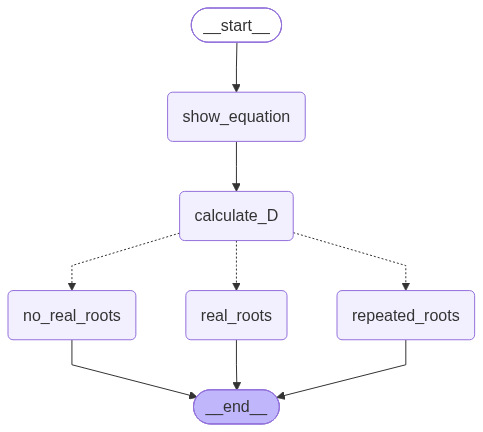

In [8]:
workflow

In [10]:
output_state=workflow.invoke({'a':4,'b':2,'c':4})
print(output_state)

{'a': 4, 'b': 2, 'c': 4, 'D': -60, 'equation': '4x^2 + 2x + 4 = 0', 'result': 'No real roots'}
